# Fase E – Comportamenti economici e temporali (RQ3)

**RQ3: il core cross-layer ha comportamenti transazionali distintivi?**

Come chiede il piano, non si guarda solo al core: si confrontano sei gruppi di wallet, che non si sovrappongono.

| Gruppo | Definizione |
|---|---|
| **Core cross-layer** | nel top 1% per forza in entrambi i layer |
| **Hub specialisti** (username / numeri) | nel top 1% di un solo layer |
| **Cross-layer** | presenti in entrambi i layer, fuori dal top 1% |
| **Specialisti** (username / numeri) | presenti in un solo layer, fuori dal top 1% |

Rete: `senza_contratti`. Richiede `fase_b_reti.ipynb`, `fase_c_intra_layer.ipynb` e `fase_d_inter_layer.ipynb`.

**Avvertenze del piano**: un wallet non è necessariamente una persona; il prezzo assente non vuol dire regalo; il volume non è profitto; i possessi ancora aperti non hanno una durata osservabile; i gruppi hanno attività ed età molto diverse, quindi i confronti finali sono fatti a parità approssimata di attività e anno di ingresso.

## 0. Dati e gruppi

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from analisi_utils import *

stile()
V = 'senza_contratti'
TOP_Q = 0.01
N_PERM = 200
A, B = LAYERS
cart = cartella_variante(V)

WL = pd.read_parquet(cart / 'wallet_layer.parquet')
CENTR = pd.read_parquet(cart / 'centralita.parquet')
EV = pd.read_parquet(cart / 'transfer_events.parquet', columns=['layer', 'nft', 'src', 'dst', 'ts', 'tipo_riga', 'event_type', 'is_purchase', 'price_ton'])
EV = EV[EV.tipo_riga != 'B -> B']
POSS = pd.read_parquet(cart / 'holding_periods.parquet', columns=['layer', 'nft', 'wallet', 'acquired_at', 'status', 'holding_days'])
CAT = pd.read_parquet(DATI / 'fragment_final.parquet', columns=['nft', 'layer', 'categories']).drop_duplicates('nft')
FINE = EV.ts.max()

attivi_ = {l: CENTR[(CENTR.layer == l) & (CENTR.grado > 0)].set_index('wallet').forza for l in LAYERS}
INF = {l: set(s.nlargest(int(round(TOP_Q * len(s)))).index) for l, s in attivi_.items()}
presenza = WL.pivot_table(index='wallet', columns='layer', values='n_eventi', aggfunc='size').notna()
wallet = presenza.index
inf = pd.DataFrame({l: wallet.isin(list(INF[l])) for l in LAYERS}, index=wallet)

gruppo = pd.Series('', index=wallet, dtype=object)
for l, altro in [(A, B), (B, A)]:
    gruppo[presenza[l] & ~presenza[altro]] = f'Specialisti {NOME[l].lower()}'
    gruppo[inf[l] & ~inf[altro]] = f'Hub specialisti {NOME[l].lower()}'
gruppo[presenza[A] & presenza[B] & ~inf[A] & ~inf[B]] = 'Cross-layer'
gruppo[inf[A] & inf[B]] = 'Core cross-layer'
ORDINE = ['Core cross-layer', f'Hub specialisti {NOME[A].lower()}', f'Hub specialisti {NOME[B].lower()}', 'Cross-layer',
          f'Specialisti {NOME[A].lower()}', f'Specialisti {NOME[B].lower()}']
COLORE = dict(zip(ORDINE, [COLORI['cross'], COLORI[A], COLORI[B], COLORI['cross'], COLORI[A], COLORI[B]]))
ALFA = dict(zip(ORDINE, [0.75, 0.75, 0.75, 0.28, 0.28, 0.28]))
gruppo = gruppo.rename('gruppo')
assert (gruppo != '').all()
salva = gruppo.value_counts().reindex(ORDINE).rename('wallet').to_frame()
salva['con archi'] = [gruppo[gruppo == g].index.isin(list(set(attivi_[A].index) | set(attivi_[B].index))).sum() for g in ORDINE]
gruppo.to_frame().to_parquet(cart / 'gruppi_wallet.parquet')
salva_tabella(salva, 'e_gruppi')
leggibile(salva)

,wallet,con archi
gruppo,,
Core cross-layer,234,234
Hub specialisti username,2.932,2.932
Hub specialisti numeri,1.010,1.010
Cross-layer,32.415,32.040
Specialisti username,309.953,283.936
Specialisti numeri,98.642,90.393


In [2]:
def etichetta(g, n=None):
    testo = g.replace(' ', '\n', 1)
    return testo + (f'\n(n={n:,})'.replace(',', '.') if n is not None else '')

def box_gruppi(ax, tabella, col, gruppi=ORDINE, log=False, titolo=None, minimo=0.01):
    dati = [tabella.loc[tabella.gruppo == g, col].dropna().to_numpy(dtype=float) for g in gruppi]
    dati = [np.clip(d, minimo, None) if log else d for d in dati]
    if log:
        ax.set_yscale('log')
    bp = ax.boxplot(dati, patch_artist=True, widths=0.55, showfliers=False, medianprops={'color': INK, 'linewidth': 1.5},
                    whiskerprops={'color': '#c3c2b7'}, capprops={'color': '#c3c2b7'})
    for scatola, g in zip(bp['boxes'], gruppi):
        scatola.set_facecolor(COLORE[g]); scatola.set_alpha(ALFA[g]); scatola.set_edgecolor(COLORE[g])
    ax.set_xticks(range(1, len(gruppi) + 1), [etichetta(g, len(d)) for g, d in zip(gruppi, dati)], fontsize=7.2)
    ax.grid(axis='x', visible=False)
    ax.set_title(titolo or col)

## 1. Attività

Eventi, NFT distinti, controparti e giorni attivi per wallet, più una misura **normalizzata per esposizione**: passaggi per mese osservato, dal primo evento del wallet alla fine dei dati (almeno un mese).

,wallet,eventi,nft_distinti,controparti,giorni_attivi,eventi_al_mese,quota_senza_prezzo
gruppo,,,,,,,
Core cross-layer,234,810,364,180.5,144.5,29.73,0.8534
Hub specialisti username,2932,210,100,60,60,12.73,0.9361
Hub specialisti numeri,1010,304,149,72.5,40,11.44,0.8013
Cross-layer,32415,10,6,4,5,0.4605,0.75
Specialisti username,309953,2,1,2,2,0.255,1
Specialisti numeri,98642,2,1,1,2,0.07277,1


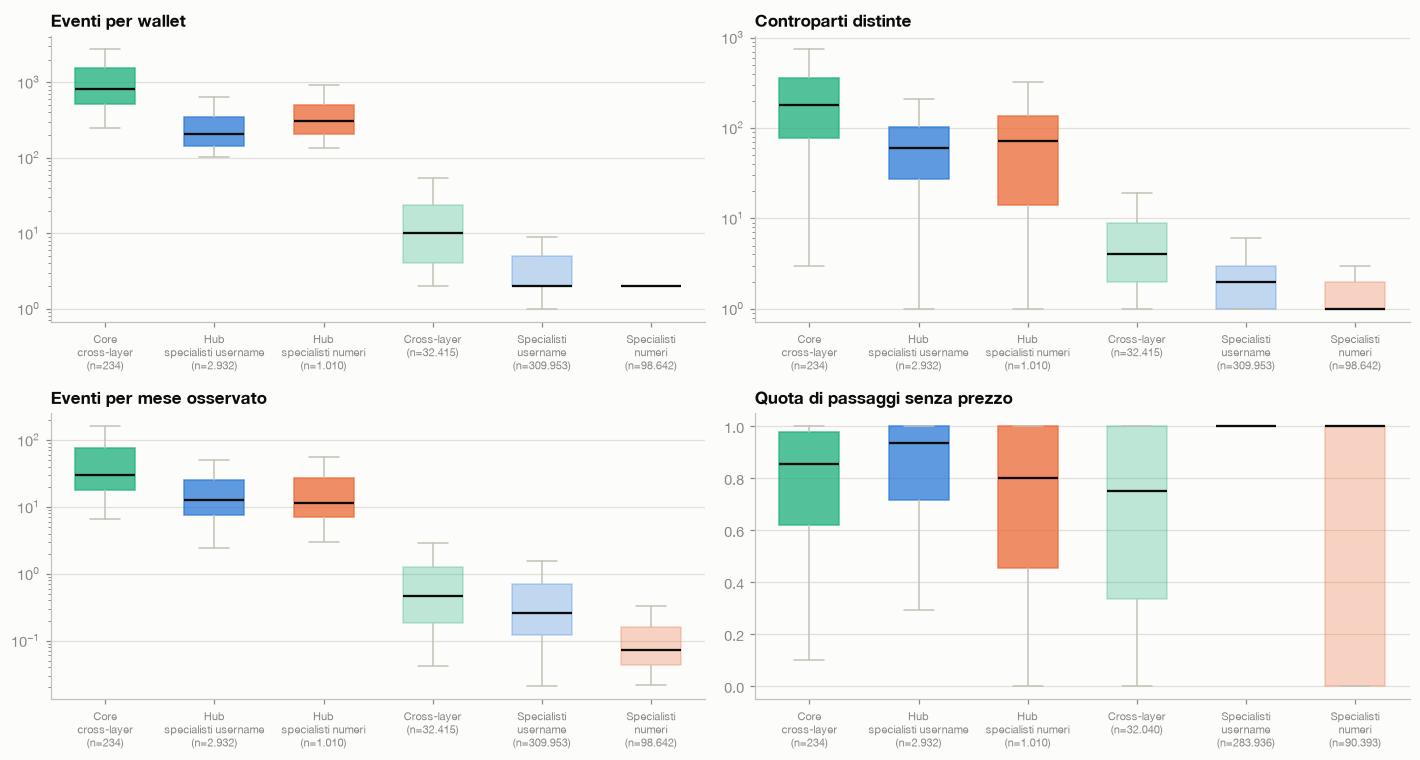

In [3]:
lunga = pd.concat([EV[['dst', 'nft', 'ts', 'src']].set_axis(['wallet', 'nft', 'ts', 'controparte'], axis=1),
                   EV[EV.tipo_riga == 'A -> B'][['src', 'nft', 'ts', 'dst']].set_axis(['wallet', 'nft', 'ts', 'controparte'], axis=1)])
lunga['giorno'] = lunga.ts.dt.floor('D')
W = lunga.groupby('wallet').agg(eventi=('nft', 'size'), nft_distinti=('nft', 'nunique'), controparti=('controparte', 'nunique'),
                                giorni_attivi=('giorno', 'nunique'), primo=('ts', 'min'))
W['gruppo'] = gruppo.reindex(W.index)
W['mesi_osservati'] = np.maximum(1.0, (FINE - W.primo).dt.total_seconds() / (86400 * 30.44))
W['eventi_al_mese'] = W.eventi / W.mesi_osservati
somme = WL.groupby('wallet')[['n_ricevuti', 'n_ceduti', 'n_acquisti', 'n_vendite']].sum()
ev_p = EV[EV.tipo_riga == 'A -> B']
trasf = pd.concat([ev_p.loc[~ev_p.is_purchase, 'src'], ev_p.loc[~ev_p.is_purchase, 'dst']]).value_counts()
tot = pd.concat([ev_p.src, ev_p.dst]).value_counts()
W['quota_senza_prezzo'] = (trasf.reindex(tot.index).fillna(0) / tot).reindex(W.index)
W['anno_ingresso'] = W.primo.dt.year
del lunga

VAR = ['eventi', 'nft_distinti', 'controparti', 'giorni_attivi', 'eventi_al_mese', 'quota_senza_prezzo']
tab = W.groupby('gruppo')[VAR].median().reindex(ORDINE)
tab.insert(0, 'wallet', W.gruppo.value_counts().reindex(ORDINE))
salva_tabella(tab, 'e_attivita_mediane')
display(tab)
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (col, tit, lg) in zip(axes.flat, [('eventi', 'Eventi per wallet', True), ('controparti', 'Controparti distinte', True),
                                          ('eventi_al_mese', 'Eventi per mese osservato', True), ('quota_senza_prezzo', 'Quota di passaggi senza prezzo', False)]):
    box_gruppi(ax, W, col, log=lg, titolo=tit, minimo=0.01 if col == 'eventi_al_mese' else 1)
fig.tight_layout()
salva_figura(fig, 'e_attivita')
plt.show()

## 2. Economia

Prezzi delle azioni classificate come acquisti, confrontati **dentro ogni layer** perché i livelli di prezzo sono molto diversi. I prezzi vengono dal file finale così come sono; distribuzione molto asimmetrica, quindi si usano le mediane. Il volume è la somma dei prezzi verificabili: non è un profitto.

prezzi per layer (TON):


,count,mean,std,min,50%,90%,99%,99.9%,max
layer,,,,,,,,,
phone_numbers,2.2e+05,1053,7.158e+04,0.5,155,1370,2650,1.654e+04,1e+07
usernames,8.394e+05,148.3,5206,0,10,104,1602,1.054e+04,3e+06


wallet con almeno una vendita prezzo pagato (mediana degli eventi) prezzo incassato (mediana degli eventi) volume comprato (TON) volume comprato senza lo 0,1% più alto  \
layer    gruppo                                                                                                                                                                                               
Username Core cross-layer              234                    137                                   10                                       7              7.45e+06                               6.59e+06   
         Hub specialisti username    2.932                  1.573                                   10                                       7              2.26e+07                               1.54e+07   
         Cross-layer                32.415                  5.360                                   10                                       8              5.07e+07                               2.29e+07   
         Specialisti username      309.953                 25.092                                   10                                       6              4.16e+07                               1.88e+07   
Numeri   Core cross-layer              234                    161                                  227                                     200              2.59e+07                               1.27e+07   
         Hub specialisti numeri      1.010                    604                                  159                                     156                 5e+07                               2.27e+07   
         Cross-layer                32.415                 10.255                                  159                                     159              4.22e+07                               2.75e+07   
         Specialisti numeri         98.642                 22.221                                  126                                     141              1.08e+08                               2.26e+07   

                                  quota del volume comprato del layer quota degli acquisti del layer  
layer    gruppo                                                                                       
Username Core cross-layer                                      0.0598                          0.062  
         Hub specialisti username                               0.182                          0.357  
         Cross-layer                                            0.407                          0.166  
         Specialisti username                                   0.334                          0.406  
Numeri   Core cross-layer                                       0.112                          0.111  
         Hub specialisti numeri                                 0.216                          0.269  
         Cross-layer                                            0.182                          0.283  
         Specialisti numeri                                     0.467                          0.314

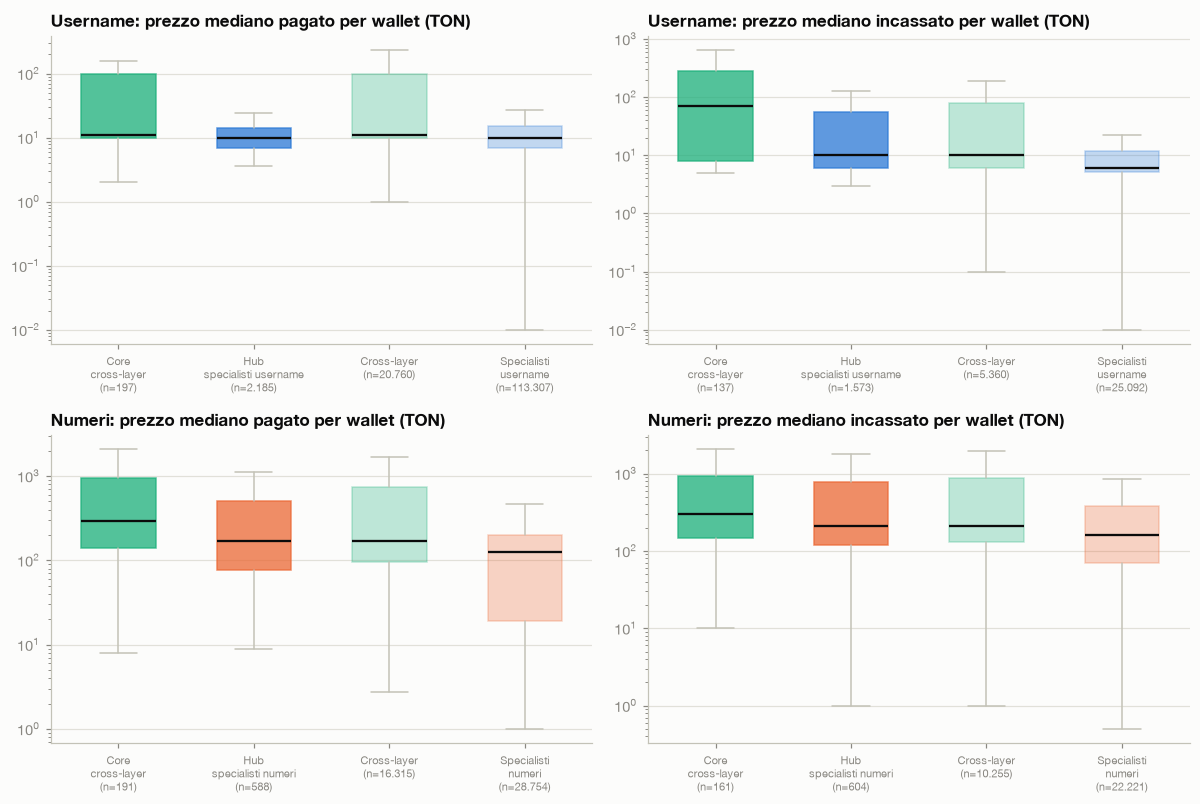

In [4]:
vendite = EV[EV.is_purchase & EV.price_ton.notna()]
soglia = vendite.groupby('layer').price_ton.quantile(0.999)
print('prezzi per layer (TON):')
display(vendite.groupby('layer').price_ton.describe(percentiles=[.5, .9, .99, .999]))

def per_layer(l):
    v = vendite[vendite.layer == l]
    t = WL[WL.layer == l].set_index('wallet')[['n_eventi', 'n_acquisti', 'n_vendite', 'volume_acquisti', 'volume_vendite']].copy()
    t['prezzo_pagato'] = v.groupby('dst').price_ton.median()
    t['prezzo_incassato'] = v[v.tipo_riga == 'A -> B'].groupby('src').price_ton.median()
    t['gruppo'] = gruppo.reindex(t.index)
    return t

ECO = {l: per_layer(l) for l in LAYERS}
GRUPPI_L = {l: ['Core cross-layer', f'Hub specialisti {NOME[l].lower()}', 'Cross-layer', f'Specialisti {NOME[l].lower()}'] for l in LAYERS}
righe = []
for l in LAYERS:
    v = vendite[vendite.layer == l]
    for g in GRUPPI_L[l]:
        t = ECO[l][ECO[l].gruppo == g]
        idx = t.index
        comprate = v[v.dst.isin(idx)]
        vendute = v[v.src.isin(idx)]
        righe.append({'layer': NOME[l], 'gruppo': g, 'wallet': len(t), 'con almeno una vendita': int((t.n_vendite > 0).sum()),
                      'prezzo pagato (mediana degli eventi)': comprate.price_ton.median(), 'prezzo incassato (mediana degli eventi)': vendute.price_ton.median(),
                      'volume comprato (TON)': comprate.price_ton.sum(), 'volume comprato senza lo 0,1% più alto': comprate.loc[comprate.price_ton <= soglia[l], 'price_ton'].sum(),
                      'quota del volume comprato del layer': comprate.price_ton.sum() / v.price_ton.sum(),
                      'quota degli acquisti del layer': len(comprate) / len(v)})
tab = pd.DataFrame(righe).set_index(['layer', 'gruppo'])
salva_tabella(tab, 'e_economia')
display(leggibile(tab))

fig, axes = plt.subplots(2, 2, figsize=(11, 7.4))
for riga, l in zip(axes, LAYERS):
    box_gruppi(riga[0], ECO[l], 'prezzo_pagato', GRUPPI_L[l], log=True, titolo=f'{NOME[l]}: prezzo mediano pagato per wallet (TON)')
    box_gruppi(riga[1], ECO[l], 'prezzo_incassato', GRUPPI_L[l], log=True, titolo=f'{NOME[l]}: prezzo mediano incassato per wallet (TON)')
fig.tight_layout()
salva_figura(fig, 'e_economia')
plt.show()

## 3. Tempo di possesso

Periodi di possesso per layer e gruppo. Le durate definitive sono i periodi `COMPLETE`; `INFERRED` (passaggio attraverso un contratto) è solo un confronto di sensibilità; `OPEN` è separato. Poiché i possessi più lunghi sono spesso ancora aperti, le mediane sui soli conclusi sono troppo basse: la **curva di Kaplan-Meier** tratta i periodi aperti come censurati alla fine dei dati.

periodi conclusi (COMPLETE) quota aperti (OPEN) mediana COMPLETE (giorni) mediana con INFERRED (giorni) mediana Kaplan-Meier (giorni) possessi conclusi entro 1 giorno
layer    gruppo                                                                                                                                                                                            
Username Core cross-layer             96.545              82.365               0.146                      6.22                          6.23                          12.8                            0.321
         Hub specialisti username    642.625             527.651               0.167                      5.64                          5.91                          13.3                            0.334
         Cross-layer                 261.660             147.528               0.433                      21.7                          21.9                           290                            0.261
         Specialisti username      1.012.275             694.292               0.311                      4.59                          4.63                          29.2                             0.38
Numeri   Core cross-layer             88.025              83.854              0.0442                      1.19                           1.2                           1.5                            0.477
         Hub specialisti numeri      251.628             226.800              0.0915                      12.7                          12.8                          21.6                            0.266
         Cross-layer                 167.007             125.748               0.239                      24.8                          24.9                          87.8                            0.246
         Specialisti numeri          226.720             157.424                 0.3                        30                            30                           169                             0.26

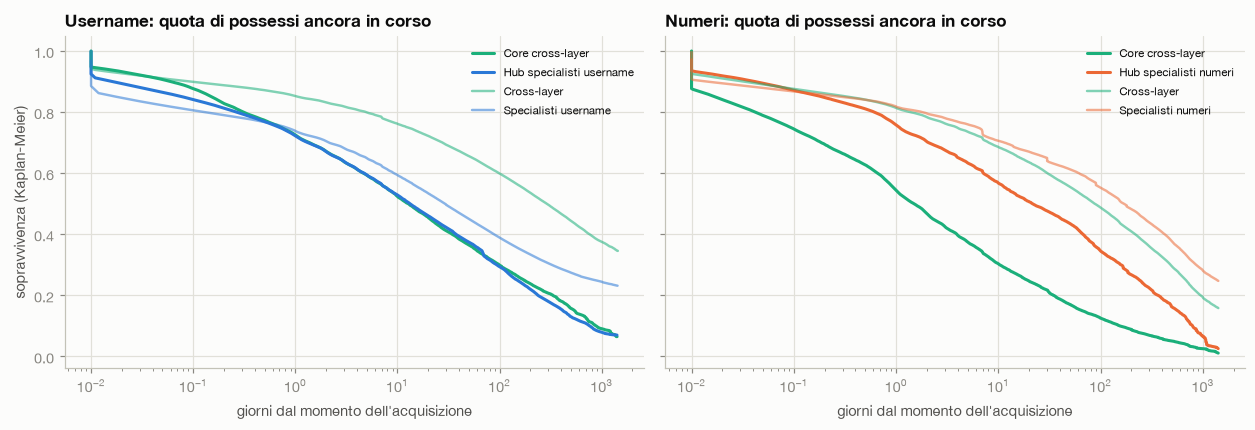

In [5]:
def kaplan_meier(durate, evento):
    ordine = np.argsort(durate)
    d, e = durate[ordine], evento[ordine]
    tempi, primo = np.unique(d, return_index=True)
    a_rischio = len(d) - primo
    morti = np.add.reduceat(e.astype(float), primo)
    return tempi, np.cumprod(1 - morti / a_rischio)

POSS['gruppo'] = POSS.wallet.map(gruppo)
POSS['censurata'] = (FINE - POSS.acquired_at).dt.total_seconds() / 86400
righe, CURVE = [], {}
for l in LAYERS:
    for g in GRUPPI_L[l]:
        t = POSS[(POSS.layer == l) & (POSS.gruppo == g)]
        conc = t[t.status == 'COMPLETE'].holding_days
        tutti = t[t.status != 'INFERRED']
        durate = np.where(tutti.status == 'OPEN', tutti.censurata, tutti.holding_days)
        tempi, sopr = kaplan_meier(durate, (tutti.status != 'OPEN').to_numpy())
        CURVE[(l, g)] = (tempi, sopr)
        sotto = np.flatnonzero(sopr <= 0.5)
        righe.append({'layer': NOME[l], 'gruppo': g, 'periodi': len(t), 'conclusi (COMPLETE)': len(conc), 'quota aperti (OPEN)': (t.status == 'OPEN').mean(),
                      'mediana COMPLETE (giorni)': conc.median(), 'mediana con INFERRED (giorni)': t[t.status != 'OPEN'].holding_days.median(),
                      'mediana Kaplan-Meier (giorni)': tempi[sotto[0]] if len(sotto) else np.nan,
                      'possessi conclusi entro 1 giorno': (conc <= 1).mean()})
tab = pd.DataFrame(righe).set_index(['layer', 'gruppo'])
salva_tabella(tab, 'e_possesso')
display(leggibile(tab))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), sharey=True)
for ax, l in zip(axes, LAYERS):
    for g in GRUPPI_L[l]:
        tempi, sopr = CURVE[(l, g)]
        passo = max(1, len(tempi) // 1500)
        stile_l = {'color': COLORE[g], 'alpha': 1 if ALFA[g] > 0.5 else 0.55, 'linewidth': 2 if ALFA[g] > 0.5 else 1.6}
        ax.plot(np.maximum(tempi[::passo], 0.01), sopr[::passo], label=g, **stile_l)
    ax.set_xscale('log')
    ax.set_title(f'{NOME[l]}: quota di possessi ancora in corso')
    ax.set_xlabel('giorni dal momento dell\'acquisizione')
    ax.legend(fontsize=7.5)
axes[0].set_ylabel('sopravvivenza (Kaplan-Meier)')
fig.tight_layout()
salva_figura(fig, 'e_possesso_km')
plt.show()

## 4. Preferenze

Per ogni wallet e layer, sugli NFT distinti posseduti (categorie multi-label, un NFT conta per ogni sua categoria):
* **numero di categorie** e **entropia** normalizzata del mix, calcolate sui wallet con almeno 5 NFT, perché con pochi NFT l'entropia è bassa per costruzione;
* **quota di NFT rari**: NFT con almeno una categoria che riguarda meno dell'1% degli NFT del layer (`No_Categories` esclusa).

wallet con almeno 5 NFT categorie (mediana, ≥5 NFT) entropia (mediana, ≥5 NFT) quota NFT rari (media, ≥5 NFT) quota NFT rari (media, tutti)
layer    gruppo                                                                                                                                                                
Username Core cross-layer              234              234                           9                      0.751                          0.119                         0.119
         Hub specialisti username    2.932            2.932                           7                       0.83                         0.0343                        0.0343
         Cross-layer                32.415           12.312                           5                       0.89                         0.0693                        0.0699
         Specialisti username      309.953           47.491                           4                       0.91                         0.0202                        0.0214
Numeri   Core cross-layer              234              234                          11                      0.589                         0.0625                        0.0625
         Hub specialisti numeri      1.010            1.006                           7                      0.593                         0.0302                        0.0301
         Cross-layer                32.415            7.321                           3                      0.836                         0.0571                        0.0481
         Specialisti numeri         98.642            7.800                           3                      0.835                          0.023                        0.0272

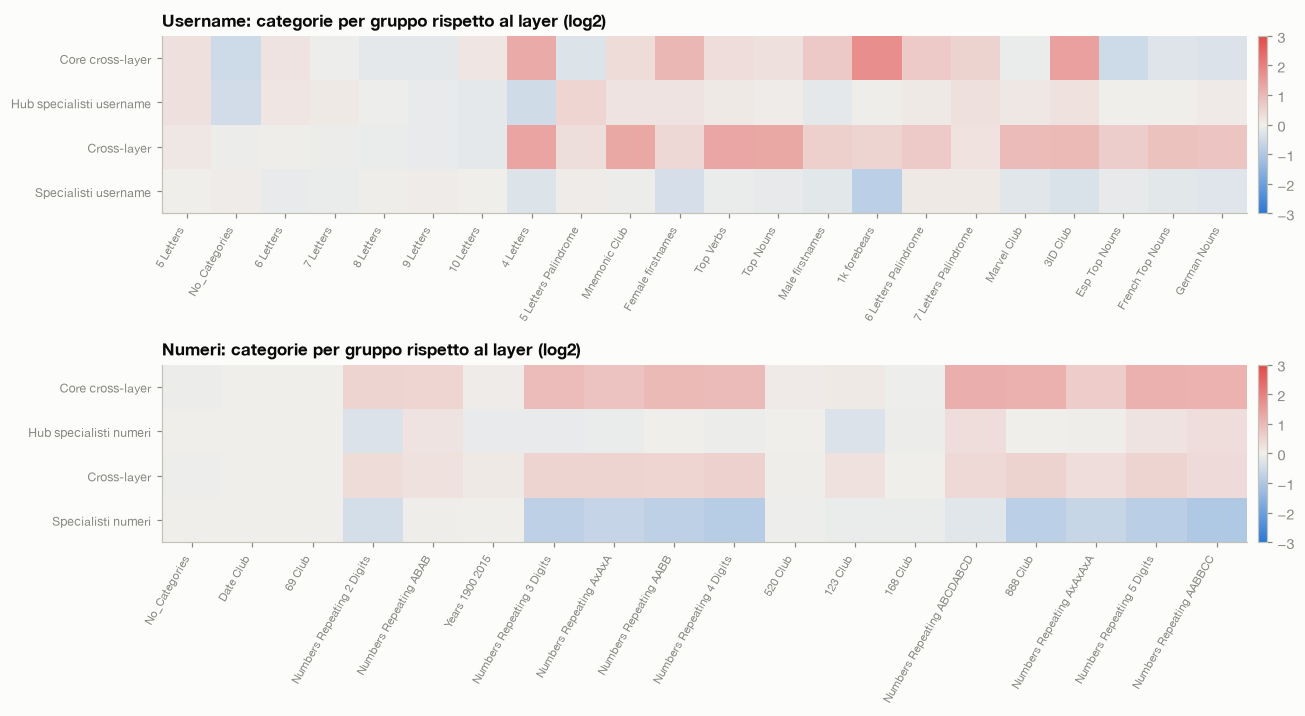

In [6]:
portafoglio = POSS[['layer', 'wallet', 'nft']].drop_duplicates()
esplosa = CAT.explode('categories').rename(columns={'categories': 'categoria'}).drop(columns='layer')
pc = portafoglio.merge(esplosa, on='nft')
n_nft_layer = CAT.groupby('layer').size()
quota_cat = esplosa.merge(CAT[['nft', 'layer']], on='nft').groupby(['layer', 'categoria']).size().rename('n').reset_index()
quota_cat['quota'] = quota_cat.n / quota_cat.layer.map(n_nft_layer)
quota_cat['rara'] = (quota_cat.quota < 0.01) & (quota_cat.categoria != 'No_Categories')
salva_tabella(quota_cat, 'e_categorie_frequenze', index=False)
pc = pc.merge(quota_cat[['layer', 'categoria', 'rara']], on=['layer', 'categoria'])

conte = pc.groupby(['layer', 'wallet', 'categoria']).size().rename('n').reset_index()
tot_w = conte.groupby(['layer', 'wallet']).n.transform('sum')
conte['h'] = -(conte.n / tot_w) * np.log(conte.n / tot_w)
PREF = conte.groupby(['layer', 'wallet']).agg(n_categorie=('categoria', 'nunique'), h=('h', 'sum'))
PREF['entropia'] = np.where(PREF.n_categorie > 1, PREF.h / np.log(PREF.n_categorie.clip(lower=2)), 0.0)
PREF['nft'] = portafoglio.groupby(['layer', 'wallet']).nft.nunique()
PREF['quota_rari'] = pc[pc.rara].groupby(['layer', 'wallet']).nft.nunique().reindex(PREF.index).fillna(0) / PREF.nft
PREF = PREF.reset_index()
PREF['gruppo'] = PREF.wallet.map(gruppo)

righe = []
for l in LAYERS:
    for g in GRUPPI_L[l]:
        t = PREF[(PREF.layer == l) & (PREF.gruppo == g)]
        q = t[t.nft >= 5]
        righe.append({'layer': NOME[l], 'gruppo': g, 'wallet': len(t), 'con almeno 5 NFT': len(q), 'categorie (mediana, ≥5 NFT)': q.n_categorie.median(),
                      'entropia (mediana, ≥5 NFT)': q.entropia.median(), 'quota NFT rari (media, ≥5 NFT)': q.quota_rari.mean(), 'quota NFT rari (media, tutti)': t.quota_rari.mean()})
tab = pd.DataFrame(righe).set_index(['layer', 'gruppo'])
salva_tabella(tab, 'e_preferenze')
display(leggibile(tab))

# mix di categorie per gruppo: quota di NFT del gruppo con la categoria / quota nel layer
blu_rosso = LinearSegmentedColormap.from_list('bluerosso', ['#2a78d6', '#f0efec', '#e34948'])
fig, axes = plt.subplots(2, 1, figsize=(12, 6.6))
for ax, l in zip(axes, LAYERS):
    t = pc[pc.layer == l].assign(gruppo=lambda x: x.wallet.map(gruppo))
    n_g = portafoglio[portafoglio.layer == l].assign(gruppo=lambda x: x.wallet.map(gruppo)).groupby('gruppo').nft.nunique()
    m = t.groupby(['gruppo', 'categoria']).nft.nunique().unstack(fill_value=0).reindex(GRUPPI_L[l])
    q_l = quota_cat[quota_cat.layer == l].set_index('categoria').sort_values('n', ascending=False)
    colonne = q_l[q_l.n >= 200].index.intersection(m.columns)
    lift = m[colonne].div(n_g.reindex(GRUPPI_L[l]), axis=0).div(q_l.quota.reindex(colonne), axis=1)
    im = ax.imshow(np.log2(lift.replace(0, np.nan)).clip(-3, 3).fillna(-3), cmap=blu_rosso, vmin=-3, vmax=3, aspect='auto')
    ax.set_xticks(range(len(colonne)), colonne, rotation=60, ha='right', fontsize=7.5)
    ax.set_yticks(range(len(GRUPPI_L[l])), GRUPPI_L[l], fontsize=8)
    ax.grid(False)
    ax.set_title(f'{NOME[l]}: categorie per gruppo rispetto al layer (log2)')
    fig.colorbar(im, ax=ax, fraction=0.015, pad=0.01)
fig.tight_layout()
salva_figura(fig, 'e_preferenze_heatmap')
plt.show()

## 5. Evoluzione

Per i wallet presenti in entrambi i layer: da quale mercato sono entrati e quanto tempo dopo sono entrati nell'altro. È una sequenza temporale osservata, non una relazione causale; i due mercati hanno età simile (primo evento: novembre e dicembre 2022).

,wallet,ritardo_mediano_giorni,entro_30_giorni,oltre_1_anno,prima numeri,prima username,stesso momento
gruppo,,,,,,,
Core cross-layer,234,10.44,0.7179,0.008547,0.4701,0.5299,0
Hub specialisti username,1054,32.38,0.4905,0.08065,0.2182,0.7808,0.0009488
Hub specialisti numeri,599,15.5,0.5977,0.06845,0.7446,0.2521,0.003339
Cross-layer,32415,14.57,0.5942,0.0865,0.537,0.4603,0.002684


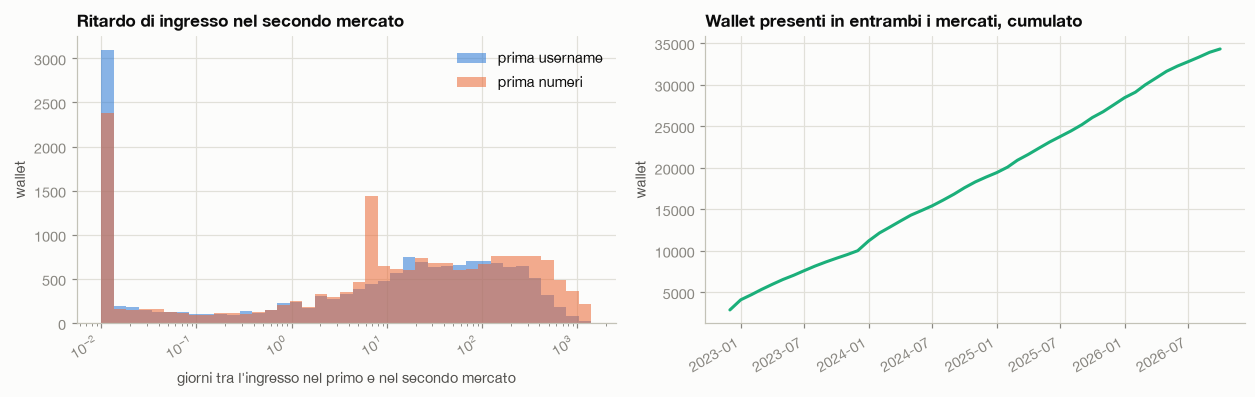

In [7]:
primo = WL.pivot_table(index='wallet', columns='layer', values='primo', aggfunc='min').dropna()
primo['gruppo'] = gruppo.reindex(primo.index)
primo['lag_giorni'] = (primo[B] - primo[A]).dt.total_seconds() / 86400
primo['ingresso'] = np.where(primo.lag_giorni > 0, f'prima {NOME[A].lower()}', np.where(primo.lag_giorni < 0, f'prima {NOME[B].lower()}', 'stesso momento'))
primo['seconda_entrata'] = primo[[A, B]].max(axis=1)
primo['ritardo'] = primo.lag_giorni.abs()
tab = primo.groupby('gruppo').agg(wallet=('ritardo', 'size'), ritardo_mediano_giorni=('ritardo', 'median'),
                                  entro_30_giorni=('ritardo', lambda x: (x <= 30).mean()), oltre_1_anno=('ritardo', lambda x: (x > 365).mean())).reindex([g for g in ORDINE if g in set(primo.gruppo)])
tab = tab.join(pd.crosstab(primo.gruppo, primo.ingresso, normalize='index'))
salva_tabella(tab, 'e_evoluzione')
display(tab)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7))
bins = np.logspace(-2, np.log10(max(primo.ritardo.max(), 1)), 40)
for nome, colore in [(f'prima {NOME[A].lower()}', COLORI[A]), (f'prima {NOME[B].lower()}', COLORI[B])]:
    axes[0].hist(np.clip(primo.loc[primo.ingresso == nome, 'ritardo'], 0.01, None), bins=bins, color=colore, alpha=0.55, label=nome)
axes[0].set_xscale('log')
axes[0].set_xlabel('giorni tra l\'ingresso nel primo e nel secondo mercato')
axes[0].set_ylabel('wallet')
axes[0].set_title('Ritardo di ingresso nel secondo mercato')
axes[0].legend()
mesi = primo.seconda_entrata.dt.tz_localize(None).dt.to_period('M').value_counts().sort_index().cumsum()
axes[1].plot(mesi.index.to_timestamp(), mesi.to_numpy(), color=COLORI['cross'])
axes[1].set_title('Wallet presenti in entrambi i mercati, cumulato')
axes[1].set_ylabel('wallet')
fig.autofmt_xdate()
fig.tight_layout()
salva_figura(fig, 'e_evoluzione')
plt.show()

## 6. Ruoli

Posizione nella rete di ogni layer:
* **percentile di PageRank** tra i wallet con archi del layer;
* **bridging**: quota dei passaggi di un wallet con wallet di altre comunità. 0 = scambia solo nella propria comunità;
* per i wallet con archi in entrambi i layer, **cambio di posizione**: differenza tra i percentili nei due layer.

percentile_pagerank  bridging  dimensione_comunita
layer    gruppo                                                                      
Username Core cross-layer                        0.993    0.1602                 3175
         Hub specialisti username               0.9921    0.0936            1.361e+04
         Cross-layer                            0.5441         0                 8831
         Specialisti username                   0.4912         0            1.371e+04
Numeri   Core cross-layer                       0.9965     0.323                 3577
         Hub specialisti numeri                  0.993    0.2366                 2658
         Cross-layer                            0.6488         0                 3577
         Specialisti numeri                     0.4469         0                 3172

,count,50%,mean
gruppo,,,
Core cross-layer,234,0.005188,0.03628
Cross-layer,2.867e+04,0.2073,0.2694
Hub specialisti numeri,579,0.1919,0.3369
Hub specialisti username,1052,0.08224,0.1726


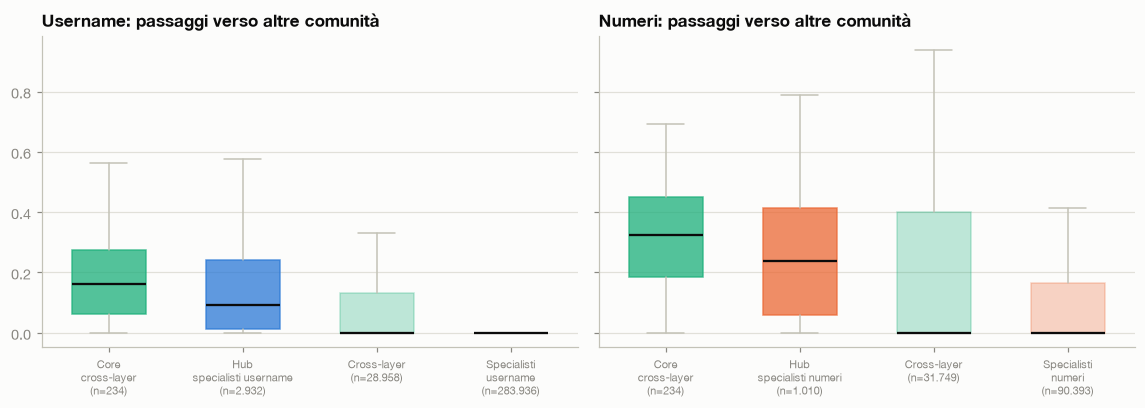

In [8]:
righe, RUOLI = [], {}
for l in LAYERS:
    com = pd.read_parquet(cart / f'comunita_{FILE[l]}.parquet').set_index('wallet').comunita
    x = pd.read_parquet(cart / f'edges_{FILE[l]}.parquet', columns=['sender', 'recipient', 'n_transfers'])
    stessa = x.sender.map(com).to_numpy() == x.recipient.map(com).to_numpy()
    interna = pd.concat([x[stessa].groupby('sender').n_transfers.sum(), x[stessa].groupby('recipient').n_transfers.sum()]).groupby(level=0).sum()
    c = CENTR[(CENTR.layer == l) & (CENTR.grado > 0)].set_index('wallet')
    t = pd.DataFrame({'percentile_pagerank': c.pagerank.rank(pct=True), 'bridging': 1 - interna.reindex(c.index).fillna(0) / c.forza,
                      'dimensione_comunita': c.index.map(com.map(com.value_counts()))}, index=c.index)
    t['gruppo'] = gruppo.reindex(t.index)
    RUOLI[l] = t
    tt = t.groupby('gruppo')[['percentile_pagerank', 'bridging', 'dimensione_comunita']].median().reindex(GRUPPI_L[l])
    righe.append(tt.assign(layer=NOME[l]).set_index('layer', append=True).swaplevel())
tab = pd.concat(righe)
salva_tabella(tab, 'e_ruoli')
display(tab)
entrambi = RUOLI[A].index.intersection(RUOLI[B].index)
sposta = pd.DataFrame({'p_a': RUOLI[A].percentile_pagerank[entrambi], 'p_b': RUOLI[B].percentile_pagerank[entrambi], 'gruppo': gruppo.reindex(entrambi)})
sposta['differenza_assoluta'] = (sposta.p_a - sposta.p_b).abs()
display(sposta.groupby('gruppo').differenza_assoluta.describe(percentiles=[.5])[['count', '50%', 'mean']])

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, l in zip(axes, LAYERS):
    box_gruppi(ax, RUOLI[l], 'bridging', GRUPPI_L[l], titolo=f'{NOME[l]}: passaggi verso altre comunità')
fig.tight_layout()
salva_figura(fig, 'e_ruoli_bridging')
plt.show()

## 7. Confronti a parità di attività

Questi sono i test su RQ3. I gruppi hanno attività ed età molto diverse, per costruzione: il core e gli hub sono i wallet più attivi. Per questo i confronti sono fatti **dentro strati** di attività (decili di eventi) e anno di ingresso; il risultato è la media delle differenze negli strati, pesata sul gruppo di interesse.

**Modello nullo** (*random attribute model*, lezione 8): si rimescolano le etichette dei gruppi dentro ogni strato. Variabili molto asimmetriche in scala log10. I p-value sono corretti con Benjamini-Hochberg.

In [9]:
def strati(t):
    return pd.qcut(t.eventi.rank(method='first'), 10, labels=False).astype(str) + '_' + t.anno_ingresso.astype(str)

def test_strati(t, col, gruppo_a, gruppo_b, n_perm=N_PERM, seed=SEED):
    t = t[t.gruppo.isin(gruppo_a + gruppo_b)].dropna(subset=[col, 'eventi', 'anno_ingresso'])
    t = t.assign(strato=strati(t), a=t.gruppo.isin(gruppo_a))
    conte = t.groupby('strato').a.agg(['sum', 'size'])
    validi = conte[(conte['sum'] > 0) & (conte['sum'] < conte['size'])].index
    t = t[t.strato.isin(validi)]
    if t.a.sum() == 0:
        return None
    gruppi = [(g[col].to_numpy(dtype=float), int(g.a.sum())) for _, g in t.groupby('strato')]
    pesi = np.array([k for _, k in gruppi], dtype=float)
    pesi /= pesi.sum()
    oss = sum(p * (x[a].mean() - x[~a].mean()) for p, (x, _), a in zip(pesi, gruppi, [g.a.to_numpy() for _, g in t.groupby('strato')]))
    rng = np.random.default_rng(seed)
    nullo = np.zeros(n_perm)
    for i in range(n_perm):
        for p, (x, k) in zip(pesi, gruppi):
            perm = rng.permutation(len(x))
            nullo[i] += p * (x[perm[:k]].mean() - x[perm[k:]].mean())
    return {'n gruppo A': int(t.a.sum()), 'n gruppo B': int((~t.a).sum()), 'differenza (A − B)': oss, 'z': z_score(oss, nullo), 'p empirico': p_empirico(oss, nullo)}

T = W.copy()
T['log10_eventi_al_mese'] = np.log10(T.eventi_al_mese)
T['log10_controparti'] = np.log10(T.controparti + 1)     # + 1: chi ha solo l'acquisto iniziale non ha controparti
poss_w = POSS[POSS.status == 'COMPLETE'].groupby('wallet').holding_days.median()
T['log10_possesso'] = np.log10(poss_w.reindex(T.index).clip(lower=0.01))
for l in LAYERS:
    T[f'log10_prezzo_pagato_{FILE[l]}'] = np.log10(ECO[l].prezzo_pagato.reindex(T.index).clip(lower=0.01))
    q = PREF[(PREF.layer == l) & (PREF.nft >= 5)].set_index('wallet')
    T[f'entropia_{FILE[l]}'] = q.entropia.reindex(T.index)
    T[f'quota_rari_{FILE[l]}'] = PREF[PREF.layer == l].set_index('wallet').quota_rari.reindex(T.index)
    T[f'bridging_{FILE[l]}'] = RUOLI[l].bridging.reindex(T.index)
VARIABILI = ['quota_senza_prezzo', 'log10_eventi_al_mese', 'log10_controparti', 'log10_possesso'] + [f'{v}_{FILE[l]}' for l in LAYERS for v in ['log10_prezzo_pagato', 'entropia', 'quota_rari', 'bridging']]
HUB = [g for g in ORDINE if g.startswith('Hub')]
SPEC = [g for g in ORDINE if g.startswith('Specialisti')]
CONFRONTI = {'Core contro hub specialisti': (['Core cross-layer'], HUB), 'Cross-layer contro specialisti': (['Cross-layer'], SPEC)}

righe = []
for nome, (ga, gb) in CONFRONTI.items():
    for v in VARIABILI:
        r = test_strati(T, v, ga, gb)
        if r:
            righe.append({'confronto': nome, 'variabile': v, **r})
TEST = pd.DataFrame(righe)
TEST['q (BH)'] = benjamini_hochberg(TEST['p empirico'])
TEST = TEST.set_index(['confronto', 'variabile'])
salva_tabella(TEST, 'e_test_a_parita_di_attivita')
TEST

n gruppo A  n gruppo B  differenza (A − B)      z  p empirico   q (BH)
confronto                      variabile                                                                                            
Core contro hub specialisti    quota_senza_prezzo                    234        1884             0.04864  2.308     0.02985  0.03412
                               log10_eventi_al_mese                  234        1884             0.03901  2.271     0.02488  0.02985
                               log10_controparti                     234        1884               0.136  3.075    0.004975 0.007463
                               log10_possesso                        234        1863             -0.1802 -2.104     0.03483  0.03799
                               log10_prezzo_pagato_usernames         197        1134              0.2625  5.292    0.004975 0.007463
                               entropia_usernames                    234        1450            -0.03301 -2.445     0.02488  0.02985
                               quota_rari_usernames                  234        1557             0.06847  6.541    0.004975 0.007463
                               bridging_usernames                    234        1549             0.01371  1.112      0.2438   0.2544
                               log10_prezzo_pagato_numbers           191         632             0.02279 0.5269      0.5771   0.5771
                               entropia_numbers                      234         802            -0.02635 -2.302      0.0199  0.02809
                               quota_rari_numbers                    234        1161             0.02138  2.719     0.02488  0.02985
                               bridging_numbers                      234        1160             0.04847  3.517    0.004975 0.007463
Cross-layer contro specialisti quota_senza_prezzo                  32040      333692            -0.05824 -26.26    0.004975 0.007463
                               log10_eventi_al_mese                32415      320393             0.03854  31.59    0.004975 0.007463
                               log10_controparti                   32415      320393             0.03404  18.88    0.004975 0.007463
                               log10_possesso                      26630      152943              0.2032  22.07    0.004975 0.007463
                               log10_prezzo_pagato_usernames       20760       86493              0.1178  16.23    0.004975 0.007463
                               entropia_usernames                  12312       47491             0.02419  9.589    0.004975 0.007463
                               quota_rari_usernames                32415      241479             0.03809  33.41    0.004975 0.007463
                               bridging_usernames                  28958      252646            -0.02054 -13.26    0.004975 0.007463
                               log10_prezzo_pagato_numbers         16315       19740             0.08271  13.93    0.004975 0.007463
                               entropia_numbers                     7321        7800             0.03821  12.58    0.004975 0.007463
                               quota_rari_numbers                  32415       85536             0.02223  13.46    0.004975 0.007463
                               bridging_numbers                    31749       78178            -0.04696 -20.61    0.004975 0.007463

## 8. Lettura (RQ3)

Valori sulla rete senza contratti. Con questi numeri di wallet quasi tutto risulta significativo, quindi conta la dimensione delle differenze; con 200 permutazioni il p-value più basso possibile è 0,005.

**Core contro hub specialisti** (234 contro circa 2.000 wallet, a parità di attività e anno di ingresso). Il core si distingue, con differenze moderate:
* più controparti (circa 1,4 volte) e possessi più brevi (circa 2/3);
* negli username paga prezzi più alti (circa 1,8 volte) e possiede più NFT rari (+6,8 punti percentuali);
* mix di categorie leggermente meno vario in entrambi i layer;
* nei numeri fa più scambi con altre comunità (+4,8 punti percentuali);
* nessuna differenza per i prezzi pagati nei numeri e per gli scambi tra comunità negli username.

**Cross-layer contro specialisti** (circa 32.000 contro oltre 300.000 wallet, stessi controlli). I cross-layer tengono gli NFT più a lungo (circa 1,6 volte), pagano di più (circa 1,3 volte negli username e 1,2 nei numeri), fanno meno passaggi senza prezzo (−5,8 punti percentuali), possiedono più NFT rari e scambiano meno con altre comunità.

**Tempo di possesso con i periodi aperti (Kaplan-Meier).** Nei numeri la mediana cresce dal core agli specialisti: 1,5 giorni per il core, 22 per gli hub specialisti, 88 per i cross-layer, 169 per gli specialisti. Negli username core e hub specialisti sono uguali (13 giorni), mentre i cross-layer arrivano a 290 e gli specialisti a 29.

**Evoluzione.** Il core entra nel secondo mercato molto presto (mediana 10 giorni, il 72% entro 30). Non c'è una direzione prevalente, mentre gli hub specialisti sono entrati prima nel mercato in cui sono hub (78% e 74%). I wallet condivisi crescono in modo regolare fino a circa 34.000. È una sequenza temporale, non un rapporto di causa.

**Ruoli.** Il core mantiene quasi la stessa posizione nei due layer (differenza mediana di percentile 0,005, contro 0,21 dei cross-layer) e ha la quota più alta di passaggi verso altre comunità (0,16 / 0,32, contro 0,09 / 0,24 degli hub specialisti e 0 degli altri gruppi).

**Economia.** I confronti di prezzo usano le mediane perché lo 0,1% dei prezzi più alti vale il 48% del volume negli username e il 62% nei numeri: i totali di volume dipendono da pochissime vendite e non vanno letti come dimensione economica dei gruppi.